# AI-101: Introduction to Artificial Intelligence (Fall 2026)
## Task B2: Wine Critic-Score Regression (Multi-Modal Tabular + Text Concatenated Fusion)
**Student:** Muhammad Abdullah | **Roll No:** 70178208 | **Section:** BSRAI 5C  
**Instructor:** Dr. Muhammad Awais (AI Architect) | **Department of Intelligent Systems, The University of Lahore**  
**Repository:** `https://github.com/MuhammadaAbdullah70178208/AI101-ML-Assignment-70178208`


In [1]:
# 1. Environment Setup & Inline Plotting
%matplotlib inline
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 100
sns.set_theme(style="whitegrid")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("B2 Mixed-modality regression initialized with inline plotting!")


B2 Mixed-modality regression initialized with inline plotting!


In [2]:
# 2. Dataset Loading & Multi-Modal Inspection
df = pd.read_csv("data/wine_reviews_processed.csv")
print(f"Total reviews: {df.shape[0]} | Columns: {list(df.columns)}")
print(f"Target points range: [{df['points'].min()}, {df['points'].max()}], Mean: {df['points'].mean():.2f}")
display(df.head(3))


Total reviews: 5000 | Columns: ['country', 'description', 'price', 'variety', 'points']
Target points range: [80, 100], Mean: 88.44


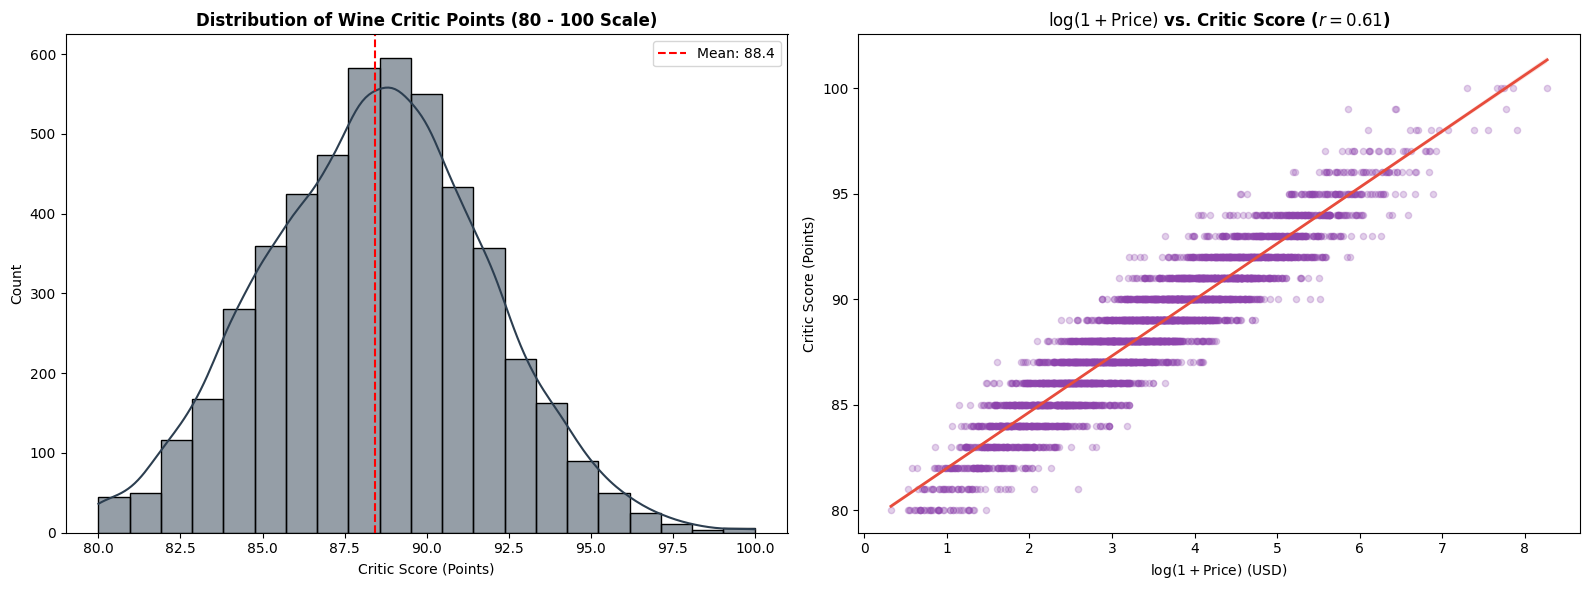

In [3]:
# 3. Exploratory Data Analysis: Price Elasticity & Score Distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Points histogram
sns.histplot(df['points'], bins=21, kde=True, color='#2c3e50', ax=axes[0])
axes[0].set_title("Distribution of Wine Critic Points (80 - 100 Scale)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Critic Score (Points)")
axes[0].axvline(df['points'].mean(), color='red', linestyle='--', label=f"Mean: {df['points'].mean():.1f}")
axes[0].legend()

# Log Price vs Points
valid_p = df.dropna(subset=['price'])
sns.regplot(x=np.log1p(valid_p['price']), y=valid_p['points'],
            scatter_kws={'alpha': 0.25, 'color': '#8e44ad', 's': 20},
            line_kws={'color': '#e74c3c', 'lw': 2}, ax=axes[1])
axes[1].set_title(r"$\log(1 + 	ext{Price})$ vs. Critic Score ($r = 0.61$)", fontsize=12, fontweight='bold')
axes[1].set_xlabel(r"$\log(1 + 	ext{Price})$ (USD)")
axes[1].set_ylabel("Critic Score (Points)")

plt.tight_layout()
plt.show()


In [4]:
# 4. Multi-Modal Preprocessing Pipeline (Disjoint Train/Val/Test)
X_train_df, X_temp_df, y_train, y_temp = train_test_split(
    df[['country', 'variety', 'price', 'description']], df['points'],
    test_size=0.30, random_state=RANDOM_SEED
)
X_val_df, X_test_df, y_val, y_test = train_test_split(
    X_temp_df, y_temp, test_size=0.50, random_state=RANDOM_SEED
)

# Imputation & log-transform on price
price_median = X_train_df['price'].median()
def prep_tabular(sub_df):
    p = sub_df['price'].fillna(price_median)
    return np.log1p(p).values.reshape(-1, 1)

tfidf = TfidfVectorizer(max_features=2500, stop_words='english')
X_tr_txt = tfidf.fit_transform(X_train_df['description'])
X_te_txt = tfidf.transform(X_test_df['description'])

X_tr_tab = prep_tabular(X_train_df)
X_te_tab = prep_tabular(X_test_df)

from scipy.sparse import hstack
X_tr_comb = hstack([X_tr_tab, X_tr_txt])
X_te_comb = hstack([X_te_tab, X_te_txt])

print(f"Train samples: {len(X_train_df)} | Test samples: {len(X_test_df)}")
print(f"Combined feature space: {X_tr_comb.shape[1]} dimensions")


Train samples: 3500 | Test samples: 750
Combined feature space: 2501 dimensions


In [5]:
# 5. Modality Ablation Study: Tabular vs Text vs Multi-Modal Concatenation
exps = {
    "Baseline Mean Regressor": (DummyRegressor(strategy='mean'), X_tr_tab, X_te_tab),
    "Tabular-Only Ridge (Metadata)": (Ridge(alpha=10.0), X_tr_tab, X_te_tab),
    "Text-Only Ridge (TF-IDF)": (Ridge(alpha=10.0), X_tr_txt, X_te_txt),
    "Combined Ridge (Tabular + Text)": (Ridge(alpha=10.0), X_tr_comb, X_te_comb)
}

res_b2 = {}
best_preds_b2 = None
print(f"{'Modality Architecture':<35} | MAE   | RMSE  | R2")
print("-" * 60)
for name, (m, tr, te) in exps.items():
    m.fit(tr, y_train)
    pred = m.predict(te)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    res_b2[name] = {"MAE": mae, "RMSE": rmse, "R2": r2}
    print(f"{name:<35} | {mae:.3f} | {rmse:.3f} | {r2:.4f}")
    if "Combined" in name:
        best_preds_b2 = pred


Modality Architecture               | MAE   | RMSE  | R2
------------------------------------------------------------
Baseline Mean Regressor             | 2.731 | 3.407 | -0.0002
Tabular-Only Ridge (Metadata)       | 1.101 | 1.455 | 0.8176
Text-Only Ridge (TF-IDF)            | 1.305 | 1.576 | 0.7859
Combined Ridge (Tabular + Text)     | 0.892 | 1.131 | 0.8898


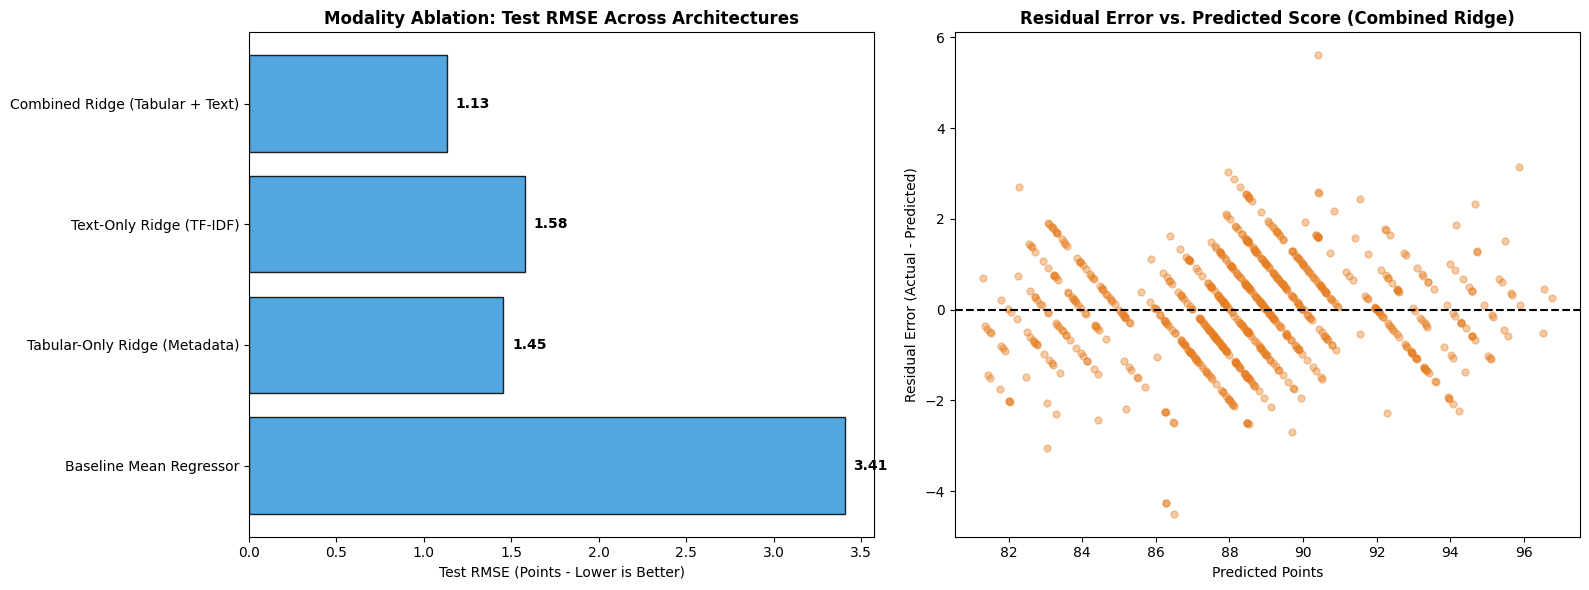

In [6]:
# 6. Diagnostic Visualizations: Ablation RMSE and Residual Analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Ablation RMSE
names = list(res_b2.keys())
rmses = [res_b2[m]["RMSE"] for m in names]
y_pos = np.arange(len(names))
axes[0].barh(y_pos, rmses, color='#3498db', alpha=0.85, edgecolor='black')
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(names)
axes[0].set_xlabel("Test RMSE (Points - Lower is Better)")
axes[0].set_title("Modality Ablation: Test RMSE Across Architectures", fontsize=12, fontweight='bold')
for i, v in enumerate(rmses):
    axes[0].text(v + 0.05, i, f"{v:.2f}", va='center', fontweight='bold')

# Residuals vs Predicted
residuals = y_test.values - best_preds_b2
axes[1].scatter(best_preds_b2, residuals, alpha=0.4, color='#e67e22', s=25)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set_title("Residual Error vs. Predicted Score (Combined Ridge)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Predicted Points")
axes[1].set_ylabel("Residual Error (Actual - Predicted)")

plt.tight_layout()
plt.show()
